<a href="https://colab.research.google.com/github/kumarsaurabh1817/Final-Computer-Vision-Training/blob/main/week6_multimodal_rag/day4_multimodal_retrieval/Week6_Day4_Colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Week 6 · Day 4 — Multimodal Retrieval

**Goal:** given a question — and optionally an image — return the right pieces of the corpus. Today every retrieval choice is scored against the ground-truth sources of the question set.

| Topic | What you will build / measure |
|---|---|
| Text-only queries | Text space only (captions-as-text) vs CLIP image space only vs **hybrid** (reciprocal-rank fusion) vs hybrid + **cross-encoder reranking** |
| Text + image queries | "Which report has a chart like this?" — image→image, image+text composed vectors, text alone |
| Cross-modal | A text query returning a figure; an image query returning related text (page-neighbour expansion) |
| Metrics by question type | Source recall@k, hit@1 and MRR for text, table, figure and text+image questions; recall vs k; latency |
| Failure analysis | The questions each strategy misses, and why |

> Runtime: **T4 GPU**, ~5 min if Day 3's index is on Drive (it is built here otherwise, ~10 min).

## 0 · Install dependencies

In [19]:
import shutil
import subprocess
import sys


def pip_install(*packages: str) -> None:
    """Install packages into the running interpreter (works in Colab and plain Python)."""
    subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", *packages])


if shutil.which("tesseract") is None and shutil.which("apt-get"):
    subprocess.run("apt-get -qq update && apt-get -qq install -y tesseract-ocr > /dev/null", shell=True, check=True)
pip_install("pymupdf>=1.24", "reportlab>=4.0", "pytesseract==0.3.13", "transformers>=4.57", "timm", "open_clip_torch>=2.24",
            "sentence-transformers>=3.0", "faiss-cpu>=1.8", "langchain-text-splitters>=0.3", "pydantic>=2.6", "accelerate>=1.0")

## 1 · Imports, configuration, and output folder

In [20]:
import json
import random
import re
import time
from collections import Counter
from pathlib import Path

import matplotlib

IN_NOTEBOOK = "ipykernel" in sys.modules
if not IN_NOTEBOOK:
    matplotlib.use("Agg")  # headless when run as a script

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch

IN_COLAB = "google.colab" in sys.modules
try:
    HERE = Path(__file__).resolve().parent
except NameError:  # running inside a notebook
    HERE = Path.cwd()

OUTPUT_DIR = Path("/content/week6_outputs/day4") if IN_COLAB else HERE.parent / "results" / "day4"
OUTPUT_DIR.mkdir(parents=True, exist_ok=True)

FULL_RUN = True
REAL_PAPERS = FULL_RUN
CORPUS_SEED = 7
LLM_BACKEND = "local"  # only used if the index has to be built here (figure captions)
VLM_ID = "Qwen/Qwen3-VL-4B-Instruct"
K = 5
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
random.seed(0)
print(f"PyTorch {torch.__version__} | device={DEVICE} | FULL_RUN={FULL_RUN}")


def save_fig(fig, name: str) -> None:
    """Save a figure to OUTPUT_DIR and show it inline when in a notebook."""
    path = OUTPUT_DIR / name
    fig.savefig(path, dpi=120, bbox_inches="tight")
    if IN_NOTEBOOK:
        plt.show()
    plt.close(fig)
    print(f"saved -> {path}")

PyTorch 2.14.1+cu130 | device=cuda | FULL_RUN=True


## 2 · Helper code (shared by Weeks 6–8; canonical copies in `tools/shared/`)

In [21]:
# ==== shared: storage ====
# ---- storage.py: shared helper code (canonical copy in week6_multimodal_rag/tools/shared/) ----
# Where files live. Colab wipes /content when the session ends, so everything a later day or week needs
# (corpus, parsed elements, index) is written to Google Drive when it is mounted:
#     My Drive/cv_course_artifacts/<name>/
# Without Drive (or when running locally) the same layout is created under cv_course_artifacts/.
import os
from pathlib import Path

USE_DRIVE = True  # Colab: mount Google Drive and keep artifacts there
DRIVE_ROOT = Path("/content/drive/MyDrive")


def get_secret(name: str) -> str | None:
    """Environment variable first, then Colab secrets (key icon in the left sidebar)."""
    if os.environ.get(name):
        return os.environ[name]
    try:
        from google.colab import userdata
        return userdata.get(name)
    except Exception:
        return None


def mount_drive() -> Path | None:
    """Mount Google Drive once (asks for permission) and return My Drive, or None outside Colab."""
    if not (IN_COLAB and USE_DRIVE):
        return None
    if not DRIVE_ROOT.exists():
        from google.colab import drive
        drive.mount("/content/drive")
    return DRIVE_ROOT if DRIVE_ROOT.exists() else None


def artifact_dir(name: str) -> Path:
    """A folder that survives the Colab session (Drive) or the repo-level cv_course_artifacts/ folder locally."""
    drive = mount_drive()
    if drive is not None:
        base = drive / "cv_course_artifacts"
    elif IN_COLAB:
        base = Path("/content/cv_course_artifacts")
    else:
        base = HERE.parent.parent / "cv_course_artifacts"
    path = base / name
    path.mkdir(parents=True, exist_ok=True)
    return path
# ==== end shared: storage ====

In [22]:
# ==== shared: corpus ====
# ---- corpus.py: shared helper code (canonical copy in week6_multimodal_rag/tools/shared/) ----
# A small multimodal document corpus with exact ground truth (Weeks 6-8).
#
# Six fictional company annual reports rendered as real PDFs with reportlab. Each has text sections, a
# quarterly results table, and charts that carry information that is NOT in the text (revenue by region,
# segment shares, headcount trend), so some questions can only be answered from the images. One report is
# "scanned" (pages rasterized, no text layer), so the parser must fall back to OCR.
# Optional extras: the first pages of a few real arXiv papers (vector figures, real tables) and your own PDFs
# from Drive (My Drive/datasets/rag_corpus/*.pdf). Those have no full ground truth; a few known facts are asked.
import io
import json
import random
import re
import shutil
import urllib.request
from dataclasses import asdict, dataclass

import matplotlib.pyplot as plt
import numpy as np
import pymupdf
from PIL import Image, ImageFilter
from reportlab.lib import colors
from reportlab.lib.pagesizes import A4
from reportlab.lib.styles import getSampleStyleSheet
from reportlab.lib.units import cm
from reportlab.platypus import Image as RLImage
from reportlab.platypus import PageBreak, Paragraph, SimpleDocTemplate, Spacer, Table, TableStyle

COMPANIES = [
    dict(doc_id="northwind_energy", name="Northwind Energy", ceo="Amara Okafor", hq="Oslo", founded=1998,
         industry="renewable energy", segments=["Wind", "Solar", "Hydro", "Grid services"], regions=["Europe", "North America", "Asia"]),
    dict(doc_id="contoso_health", name="Contoso Health", ceo="Daniel Brooks", hq="Boston", founded=2004,
         industry="digital health", segments=["Diagnostics", "Telemedicine", "Devices"], regions=["North America", "Europe", "Latin America"]),
    dict(doc_id="fabrikam_robotics", name="Fabrikam Robotics", ceo="Mei Lin Zhang", hq="Shenzhen", founded=2011,
         industry="industrial robotics", segments=["Robot arms", "Mobile robots", "Software", "Services"], regions=["Asia", "Europe", "North America"]),
    dict(doc_id="tailspin_air", name="Tailspin Air", ceo="Carlos Mendes", hq="Lisbon", founded=1987,
         industry="regional aviation", segments=["Passenger", "Cargo", "Maintenance"], regions=["Europe", "Africa", "South America"]),
    dict(doc_id="litware_software", name="Litware Software", ceo="Priya Raman", hq="Bengaluru", founded=2009,
         industry="enterprise software", segments=["Cloud", "Licences", "Consulting", "Support"], regions=["Asia", "North America", "Europe"]),
    dict(doc_id="proseware_foods", name="Proseware Foods", ceo="Hannah Keller", hq="Munich", founded=1972,
         industry="packaged foods", segments=["Dairy", "Bakery", "Beverages"], regions=["Europe", "Middle East", "Asia"], scanned=True),
]
QUARTERS = ["Q1", "Q2", "Q3", "Q4"]
YEARS = [2021, 2022, 2023, 2024, 2025]
REAL_PAPERS = {  # doc_id: (arXiv id, title, [(question, answer)] answerable from the first pages)
    "resnet": ("1512.03385", "Deep Residual Learning for Image Recognition",
               [("What error rate did the ResNet ensemble achieve on the ImageNet test set?", "3.57%")]),
    "unet": ("1505.04597", "U-Net: Convolutional Networks for Biomedical Image Segmentation",
             [("Which challenge did U-Net win in 2015?", "ISBI cell tracking challenge")]),
    "clip": ("2103.00020", "Learning Transferable Visual Models From Natural Language Supervision",
             [("How many (image, text) pairs were used to pre-train CLIP?", "400 million")]),
    "llava": ("2304.08485", "Visual Instruction Tuning",
              [("Which language-only model was used to generate LLaVA's multimodal instruction-following data?", "GPT-4")]),
    "react": ("2210.03629", "ReAct: Synergizing Reasoning and Acting in Language Models",
              [("On which two knowledge-intensive tasks is ReAct evaluated besides ALFWorld and WebShop?", ["HotpotQA", "Fever"])]),
}
FILLER = [
    "The company continued to invest in its people, its processes and its digital platforms throughout the year.",
    "Customer satisfaction remained high, and the board approved a multi-year efficiency programme.",
    "Sustainability targets were reviewed by an external auditor and published alongside this report.",
    "Supply-chain conditions normalised during the second half, easing pressure on margins.",
]


@dataclass
class ReportFacts:
    doc_id: str
    name: str
    ceo: str
    hq: str
    founded: int
    industry: str
    employees: int
    revenue: list          # Q1..Q4, USD millions
    op_profit: list        # Q1..Q4, USD millions
    segments: dict         # name -> % share (ints summing to 100)
    regions: dict          # name -> USD millions
    growth_target: int     # % for 2026
    headcount: dict | None  # year -> employees (only on some reports)
    scanned: bool = False

    @property
    def total_revenue(self) -> float:
        return round(sum(self.revenue), 1)

    @property
    def total_op_profit(self) -> float:
        return round(sum(self.op_profit), 1)

    @property
    def largest_segment(self) -> str:
        return max(self.segments, key=self.segments.get)

    @property
    def largest_region(self) -> str:
        return max(self.regions, key=self.regions.get)


def _shares_with_clear_max(rng: random.Random, n: int) -> list[int]:
    raw = sorted((rng.uniform(8, 30) for _ in range(n)), reverse=True)
    raw[0] += 12  # make the winner unambiguous on a chart
    pct = [int(round(100 * r / sum(raw))) for r in raw]
    pct[-1] += 100 - sum(pct)
    rng.shuffle(pct)
    return pct


def company_facts(c: dict, idx: int, seed: int) -> ReportFacts:
    rng = random.Random(f"{seed}-{c['doc_id']}")
    base = rng.uniform(80, 600)
    revenue = [round(base * rng.uniform(0.82, 1.25), 1) for _ in QUARTERS]
    op_profit = [round(r * rng.uniform(0.07, 0.22), 1) for r in revenue]
    total = sum(revenue)
    reg_pct = _shares_with_clear_max(rng, len(c["regions"]))
    regions = {r: round(total * p / 100, 1) for r, p in zip(c["regions"], reg_pct)}
    segments = dict(zip(c["segments"], _shares_with_clear_max(rng, len(c["segments"]))))
    employees = rng.randrange(800, 9000, 10)
    headcount = None
    if idx % 2 == 0:
        start = employees * rng.uniform(0.55, 0.8)
        headcount = {y: int(round(start + (employees - start) * i / 4, -1)) for i, y in enumerate(YEARS)}
        headcount[2025] = employees
    return ReportFacts(c["doc_id"], c["name"], c["ceo"], c["hq"], c["founded"], c["industry"], employees, revenue, op_profit,
                       segments, regions, rng.choice([4, 6, 8, 10, 12, 15]), headcount, c.get("scanned", False))


def chart_png(kind: str, f: ReportFacts, style: int = 0) -> bytes:
    """Render one chart. style=0 is the report version; style=1 is a restyled copy used as a query image."""
    palette = [plt.cm.tab10.colors, plt.cm.Set2.colors][style % 2]
    figsize = {"bar": (6, 3.5), "pie": (4.5, 4.5), "line": (6, 3)}[kind]
    if style:
        figsize = (figsize[0] * 0.8, figsize[1] * 0.8)
    fig, ax = plt.subplots(figsize=figsize)
    if kind == "bar":
        names, vals = list(f.regions), list(f.regions.values())
        bars = ax.bar(names, vals, color=palette[:len(vals)])
        ax.bar_label(bars, labels=[f"{v:.1f}" for v in vals], fontsize=9)
        ax.set_title("Revenue by region, 2025 (USD millions)" if not style else "Regional revenue")
        ax.set_ylim(0, max(vals) * 1.2)
    elif kind == "pie":
        ax.pie(list(f.segments.values()), labels=list(f.segments), autopct="%d%%", colors=palette, startangle=90 + 40 * style)
        ax.set_title("Revenue share by segment, 2025" if not style else "Segment mix")
    else:
        ys, vs = list(f.headcount), list(f.headcount.values())
        ax.plot(ys, vs, marker="o", color=palette[0])
        for y, v in zip(ys, vs):
            ax.annotate(f"{v:,}", (y, v), textcoords="offset points", xytext=(0, 6), ha="center", fontsize=8)
        ax.set_xticks(ys)
        ax.set_title("Employees 2021-2025")
        ax.set_ylim(0, max(vs) * 1.25)
    buf = io.BytesIO()
    fig.savefig(buf, format="png", dpi=110, bbox_inches="tight")
    plt.close(fig)
    return buf.getvalue()


def _rl_image(png: bytes, width_cm: float) -> RLImage:
    w, h = Image.open(io.BytesIO(png)).size
    return RLImage(io.BytesIO(png), width=width_cm * cm, height=width_cm * cm * h / w)


def build_report_pdf(f: ReportFacts, path: Path) -> None:
    st = getSampleStyleSheet()
    cap = st["Italic"]
    body = st["BodyText"]
    rng = random.Random(f.doc_id)
    story = [
        Paragraph(f"{f.name} Annual Report 2025", st["Title"]),
        Paragraph("Company overview", st["Heading2"]),
        Paragraph(f"{f.name} is a {f.industry} company headquartered in {f.hq}, founded in {f.founded}. Chief executive "
                  f"officer {f.ceo} leads a workforce of {f.employees:,} employees across its operations.", body),
        Paragraph(" ".join(rng.sample(FILLER, 2)), body),
        Paragraph("Strategy", st["Heading2"]),
        Paragraph(f"In 2025 {f.name} focused on operational efficiency and on expanding its {f.industry} portfolio. "
                  + " ".join(rng.sample(FILLER, 2)), body),
        PageBreak(),
        Paragraph("Financial results", st["Heading2"]),
        Paragraph(f"Full-year revenue reached USD {f.total_revenue:,.1f} million and operating profit USD {f.total_op_profit:,.1f} "
                  "million. Table 1 shows the quarterly results; Figure 1 breaks revenue down by region.", body),
        Spacer(1, 0.3 * cm),
    ]
    rows = [["Quarter", "Revenue", "Operating profit"]] + [[q, f"{r:,.1f}", f"{p:,.1f}"] for q, r, p in zip(QUARTERS, f.revenue, f.op_profit)]
    rows.append(["Total", f"{f.total_revenue:,.1f}", f"{f.total_op_profit:,.1f}"])
    table = Table(rows, colWidths=[4 * cm, 4 * cm, 4.5 * cm])
    table.setStyle(TableStyle([("GRID", (0, 0), (-1, -1), 0.5, colors.grey), ("BACKGROUND", (0, 0), (-1, 0), colors.lightgrey),
                               ("FONTNAME", (0, 0), (-1, 0), "Helvetica-Bold"), ("FONTNAME", (0, -1), (-1, -1), "Helvetica-Bold"),
                               ("ALIGN", (1, 0), (-1, -1), "RIGHT")]))
    story += [table, Paragraph("Table 1: Quarterly results 2025 (USD millions).", cap), Spacer(1, 0.6 * cm),
              _rl_image(chart_png("bar", f), 12), Paragraph("Figure 1: Revenue by region, 2025.", cap), PageBreak(),
              Paragraph("Business segments", st["Heading2"]),
              Paragraph(f"{f.name} operates {len(f.segments)} business segments: {', '.join(f.segments)}. "
                        "Figure 2 shows how 2025 revenue was split between them.", body),
              _rl_image(chart_png("pie", f), 8), Paragraph("Figure 2: Revenue share by segment, 2025.", cap)]
    if f.headcount:
        story += [Spacer(1, 0.3 * cm), _rl_image(chart_png("line", f), 11), Paragraph("Figure 3: Employees 2021-2025.", cap)]
    story += [Paragraph("Outlook", st["Heading2"]),
              Paragraph(f"Management targets revenue growth of {f.growth_target}% in 2026, supported by new contracts and a "
                        "disciplined cost base. " + rng.choice(FILLER), body)]
    SimpleDocTemplate(str(path), pagesize=A4, topMargin=2 * cm, bottomMargin=2 * cm, title=f"{f.name} Annual Report 2025").build(story)


def rasterize_pdf(path: Path, dpi: int = 150, seed: int = 0) -> None:
    """Turn a PDF into a 'scanned' one: page images only (slight skew, blur, noise), no text layer."""
    rng = np.random.default_rng(seed)
    pages = []
    for page in pymupdf.open(path):
        pix = page.get_pixmap(dpi=dpi)
        img = Image.frombytes("RGB", (pix.width, pix.height), pix.samples)
        img = img.rotate(float(rng.uniform(-0.8, 0.8)), resample=Image.BICUBIC, fillcolor="white").filter(ImageFilter.GaussianBlur(0.6))
        arr = np.asarray(img).astype(np.float32) + rng.normal(0, 6, (img.height, img.width, 1))
        pages.append(Image.fromarray(np.clip(arr, 0, 255).astype(np.uint8)))
    pages[0].save(path, format="PDF", save_all=True, append_images=pages[1:], resolution=dpi)


def locate_pages(path: Path) -> dict:
    """Page number of each labelled element, found in the rendered PDF (before any rasterization)."""
    marks = {"overview": "Company overview", "table1": "Table 1:", "fig1": "Figure 1:", "fig2": "Figure 2:",
             "fig3": "Figure 3:", "outlook": "Outlook"}
    out = {}
    for pno, page in enumerate(pymupdf.open(path), 1):
        text = page.get_text()
        for key, needle in marks.items():
            if key not in out and needle in text:
                out[key] = pno
    return out


def download_paper(arxiv_id: str, path: Path, max_pages: int) -> bool:
    """First pages of an arXiv paper. Returns False (and the corpus simply skips it) when offline."""
    try:
        req = urllib.request.Request(f"https://arxiv.org/pdf/{arxiv_id}", headers={"User-Agent": "Mozilla/5.0 (course notebook)"})
        data = urllib.request.urlopen(req, timeout=60).read()
        doc = pymupdf.open(stream=data, filetype="pdf")
        doc.select(list(range(min(max_pages, doc.page_count))))
        doc.save(path)
        return True
    except Exception as exc:
        print(f"skipping arXiv {arxiv_id}: {exc!r}"[:160])
        return False


def _qa(qid, question, answer, qtype, sources, number=None, image_path=None) -> dict:
    return {"id": qid, "question": question, "answer": answer, "number": number, "qtype": qtype,
            "sources": [list(s) for s in sources], "image_path": image_path}


def make_qa(facts: list[ReportFacts], pages: dict, img_dir: Path, papers: list[str], seed: int) -> list[dict]:
    """Questions with expected answers and expected sources (doc_id, page, element type)."""
    rng = random.Random(seed)
    qa = []
    for f in facts:
        p, d = pages[f.doc_id], f.doc_id
        q = rng.randrange(4)
        seg = rng.choice(list(f.segments))
        qa += [
            _qa(f"{d}-ceo", f"Who is the chief executive officer of {f.name}?", f.ceo, "text", [(d, p["overview"], "text")]),
            _qa(f"{d}-hq", f"In which city is {f.name} headquartered?", f.hq, "text", [(d, p["overview"], "text")]),
            _qa(f"{d}-employees", f"How many employees does {f.name} have?", f"{f.employees:,}", "text", [(d, p["overview"], "text")], f.employees),
            _qa(f"{d}-growth", f"What revenue growth does {f.name} target for 2026?", f"{f.growth_target}%", "text",
                [(d, p["outlook"], "text")], f.growth_target),
            _qa(f"{d}-rev-{QUARTERS[q]}", f"What was {f.name}'s revenue in {QUARTERS[q]} 2025?", f"{f.revenue[q]:,.1f}", "table",
                [(d, p["table1"], "table")], f.revenue[q]),
            _qa(f"{d}-op-{QUARTERS[3 - q]}", f"What was {f.name}'s operating profit in {QUARTERS[3 - q]} 2025?",
                f"{f.op_profit[3 - q]:,.1f}", "table", [(d, p["table1"], "table")], f.op_profit[3 - q]),
            _qa(f"{d}-region", f"Which region generated the most revenue for {f.name} in 2025?", f.largest_region, "figure",
                [(d, p["fig1"], "figure")]),
            _qa(f"{d}-segment", f"Which business segment had the largest share of {f.name}'s 2025 revenue?", f.largest_segment, "figure",
                [(d, p["fig2"], "figure")]),
            _qa(f"{d}-segshare", f"What percentage of {f.name}'s 2025 revenue came from its {seg} segment?", f"{f.segments[seg]}%",
                "figure", [(d, p["fig2"], "figure")], f.segments[seg]),
        ]
        if f.headcount:
            qa.append(_qa(f"{d}-hc2021", f"How many employees did {f.name} have in 2021 according to its headcount chart?",
                          f"{f.headcount[2021]:,}", "figure", [(d, p["fig3"], "figure")], f.headcount[2021]))
        kind = rng.choice(["pie", "bar"])
        img_path = img_dir / f"query_{d}_{kind}.png"
        img_path.write_bytes(chart_png(kind, f, style=1))
        qa.append(_qa(f"{d}-img-{kind}", "Which company's annual report contains a chart showing the same data as this image?", f.name,
                      "text+image", [(d, p["fig2" if kind == "pie" else "fig1"], "figure")], image_path=str(img_path)))
    for f in rng.sample(facts, 3):
        qa.append(_qa(f"{f.doc_id}-unans-2019", f"What was {f.name}'s revenue in 2019?", None, "unanswerable", []))
        qa.append(_qa(f"{f.doc_id}-unans-cfo", f"Who is the chief financial officer of {f.name}?", None, "unanswerable", []))
    for _ in range(4):  # multi-hop (Week 7): two documents or two elements
        a, b = rng.sample(facts, 2)
        win = a if a.revenue[3] > b.revenue[3] else b
        qa.append(_qa(f"mh-q4-{a.doc_id}-{b.doc_id}", f"Which company had the higher revenue in Q4 2025: {a.name} or {b.name}?", win.name,
                      "multi-hop", [(a.doc_id, pages[a.doc_id]["table1"], "table"), (b.doc_id, pages[b.doc_id]["table1"], "table")]))
        win = a if a.employees > b.employees else b
        qa.append(_qa(f"mh-emp-{a.doc_id}-{b.doc_id}", f"Which company has more employees, {a.name} or {b.name}, and who is its CEO?",
                      [win.name, win.ceo], "multi-hop", [(a.doc_id, pages[a.doc_id]["overview"], "text"), (b.doc_id, pages[b.doc_id]["overview"], "text")]))
    for f in rng.sample(facts, 3):
        qa.append(_qa(f"mh-regseg-{f.doc_id}", f"For {f.name}, name its largest region by revenue and its largest business segment.",
                      [f.largest_region, f.largest_segment], "multi-hop",
                      [(f.doc_id, pages[f.doc_id]["fig1"], "figure"), (f.doc_id, pages[f.doc_id]["fig2"], "figure")]))
    best = max(facts, key=lambda x: x.total_revenue)
    qa.append(_qa("mh-top-revenue-ceo", "Who is the CEO of the company with the highest full-year 2025 revenue among all the annual reports?",
                  best.ceo, "multi-hop", [(f.doc_id, pages[f.doc_id]["table1"], "table") for f in facts] + [(best.doc_id, pages[best.doc_id]["overview"], "text")]))
    for pid in papers:
        for i, (question, answer) in enumerate(REAL_PAPERS[pid][2]):
            qa.append(_qa(f"{pid}-q{i}", question, answer, "text", [(pid, 1, "text")]))
    return qa


def build_corpus(out_dir: Path, seed: int = 7, real_papers: bool = True, paper_pages: int = 4, user_pdfs: bool = True) -> tuple[list, dict, list]:
    """Write every PDF to out_dir/pdfs and return (docs, facts by doc_id, qa). Deterministic for a seed."""
    pdf_dir, img_dir = out_dir / "pdfs", out_dir / "query_images"
    pdf_dir.mkdir(parents=True, exist_ok=True)
    img_dir.mkdir(parents=True, exist_ok=True)
    facts = [company_facts(c, i, seed) for i, c in enumerate(COMPANIES)]
    docs, pages = [], {}
    for f in facts:
        path = pdf_dir / f"{f.doc_id}.pdf"
        build_report_pdf(f, path)
        pages[f.doc_id] = locate_pages(path)
        if f.scanned:
            rasterize_pdf(path, seed=seed)
        docs.append({"doc_id": f.doc_id, "path": str(path), "title": f"{f.name} Annual Report 2025",
                     "kind": "scanned report" if f.scanned else "report"})
    papers = []
    if real_papers:
        for pid, (arxiv_id, title, _) in REAL_PAPERS.items():
            path = pdf_dir / f"{pid}.pdf"
            if path.exists() or download_paper(arxiv_id, path, paper_pages):
                papers.append(pid)
                docs.append({"doc_id": pid, "path": str(path), "title": title, "kind": "arXiv paper"})
    drive = mount_drive() if user_pdfs else None
    if drive is not None and (drive / "datasets" / "rag_corpus").is_dir():
        for src in sorted((drive / "datasets" / "rag_corpus").glob("*.pdf"))[:10]:
            doc_id = re.sub(r"[^a-z0-9]+", "_", src.stem.lower()).strip("_")
            dst = pdf_dir / f"{doc_id}.pdf"
            shutil.copy(src, dst)
            docs.append({"doc_id": doc_id, "path": str(dst), "title": src.stem, "kind": "your PDF"})
    qa = make_qa(facts, pages, img_dir, papers, seed)
    (out_dir / "corpus.json").write_text(json.dumps({"docs": docs, "facts": {f.doc_id: asdict(f) for f in facts}, "pages": pages,
                                                     "qa": qa}, indent=1, default=str), encoding="utf-8")
    return docs, {f.doc_id: f for f in facts}, qa
# ==== end shared: corpus ====

In [23]:
# ==== shared: parse ====
# ---- parse.py: shared helper code (canonical copy in week6_multimodal_rag/tools/shared/) ----
# PDF -> structured elements with metadata (Week 6 Day 1, reused by every later day).
#
#     digital page:  PyMuPDF text blocks (font size -> titles) + find_tables() + raster images + clustered vector drawings
#     scanned page:  render -> Tesseract (paragraphs) + Table Transformer (table regions) + OpenCV (figure regions)
#
# Every element carries provenance: doc_id, page, bbox (PDF points, origin top-left), type, section, parser.
import re
from dataclasses import asdict, dataclass
from pathlib import Path

import cv2
import numpy as np
import pymupdf
import pytesseract
import torch
from PIL import Image


@dataclass
class Element:
    id: str
    doc_id: str
    page: int
    type: str                 # title | text | table | figure
    bbox: list                # [x0, y0, x1, y1] in PDF points
    text: str = ""            # text; table as markdown; figure: its printed caption ("Figure 2: ...")
    section: str = ""         # nearest heading above
    rows: list | None = None  # table cells
    image_path: str | None = None  # figure / table crop
    caption: str = ""         # VLM caption of a figure (Day 2)
    parser: str = "pymupdf"

    def to_dict(self) -> dict:
        return asdict(self)


def rows_to_markdown(rows: list) -> str:
    rows = [[re.sub(r"\s+", " ", str(c or "")).strip() for c in r] for r in rows if any(c for c in r)]
    if not rows:
        return ""
    w = max(len(r) for r in rows)
    rows = [r + [""] * (w - len(r)) for r in rows]
    return "\n".join(["| " + " | ".join(rows[0]) + " |", "|" + "---|" * w] + ["| " + " | ".join(r) + " |" for r in rows[1:]])


def _area(b) -> float:
    return max(0.0, b[2] - b[0]) * max(0.0, b[3] - b[1])


def overlap_frac(a, b) -> float:
    """Fraction of box a covered by box b."""
    ix = max(0.0, min(a[2], b[2]) - max(a[0], b[0]))
    iy = max(0.0, min(a[3], b[3]) - max(a[1], b[1]))
    return ix * iy / max(1e-6, _area(a))


def dedupe_boxes(boxes: list, thr: float = 0.6) -> list:
    out = []
    for b in sorted(boxes, key=_area, reverse=True):
        if not any(overlap_frac(b, o) > thr for o in out):
            out.append(b)
    return out


def vector_figure_regions(page, exclude: list, min_frac: float = 0.03, pad: int = 8) -> list:
    """Vector graphics (plots drawn as paths) -> figure boxes: paint every drawing's rect on a mask, dilate, connected components."""
    w, h = int(page.rect.width) + 1, int(page.rect.height) + 1
    mask = np.zeros((h, w), np.uint8)
    n = 0
    for d in page.get_drawings():
        r = d.get("rect")
        if r is None:
            continue
        if r.width > 0.9 * w and r.height < 4:  # full-width rule lines are not figures
            continue
        if r.width * r.height > 0.4 * w * h:  # page backgrounds and frames
            continue
        cv2.rectangle(mask, (int(r.x0), int(r.y0)), (int(r.x1), int(r.y1)), 255, -1)
        n += 1
    if n == 0:
        return []
    mask = cv2.dilate(mask, np.ones((2 * pad + 1, 2 * pad + 1), np.uint8))
    contours, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    boxes = []
    for c in contours:
        x, y, bw, bh = cv2.boundingRect(c)
        b = [x + pad / 2, y + pad / 2, x + bw - pad / 2, y + bh - pad / 2]
        if _area(b) > min_frac * w * h and not any(overlap_frac(b, e) > 0.5 for e in exclude):
            boxes.append(b)
    return boxes


def text_blocks(page) -> list[dict]:
    """PyMuPDF text blocks with the largest span size (used to tell headings from body text)."""
    out = []
    for b in page.get_text("dict")["blocks"]:
        if b.get("type") != 0:
            continue
        lines, sizes = [], []
        for line in b["lines"]:
            spans = [s for s in line["spans"] if s["text"].strip()]
            if spans:
                lines.append("".join(s["text"] for s in spans))
                sizes += [s["size"] for s in spans]
        text = re.sub(r"\s+", " ", " ".join(lines)).strip()
        if text:
            out.append({"bbox": list(b["bbox"]), "text": text, "size": max(sizes)})
    return out


def figure_caption_near(box, blocks: list[dict], max_gap: float = 70) -> str:
    """The 'Figure N: ...' text right below (or above) a figure, horizontally overlapping it."""
    best, best_gap = "", max_gap
    for b in blocks:
        if not re.match(r"^(fig(ure)?\.?\s*\d+)", b["text"], re.I):
            continue
        if min(box[2], b["bbox"][2]) - max(box[0], b["bbox"][0]) <= 0:
            continue
        gap = b["bbox"][1] - box[3] if b["bbox"][1] >= box[3] - 5 else box[1] - b["bbox"][3]
        if -5 <= gap < best_gap:
            best, best_gap = b["text"], gap
    return best


def crop_region(page, box, path: Path, dpi: int = 150) -> str:
    pix = page.get_pixmap(dpi=dpi, clip=pymupdf.Rect(*box))
    Image.frombytes("RGB", (pix.width, pix.height), pix.samples).save(path)
    return str(path)


class TableDetector:
    """Microsoft Table Transformer (DETR) table detection on page images. Loaded lazily."""

    def __init__(self, device: str = "cpu", threshold: float = 0.8):
        from transformers import AutoImageProcessor, TableTransformerForObjectDetection
        self.proc = AutoImageProcessor.from_pretrained("microsoft/table-transformer-detection")
        self.model = TableTransformerForObjectDetection.from_pretrained("microsoft/table-transformer-detection").to(device).eval()
        self.device, self.threshold = device, threshold

    @torch.inference_mode()
    def detect(self, img: Image.Image) -> list[list[float]]:
        inputs = self.proc(images=img, return_tensors="pt").to(self.device)
        out = self.model(**inputs)
        res = self.proc.post_process_object_detection(out, threshold=self.threshold, target_sizes=[img.size[::-1]])[0]
        return [b.tolist() for b, lab in zip(res["boxes"], res["labels"])
                if self.model.config.id2label[int(lab)].startswith("table")]


def figure_regions_cv(img: Image.Image, word_boxes: list, exclude: list, min_frac: float = 0.03) -> list:
    """Scanned page: ink that is not text and not a table -> figure boxes (pixels)."""
    gray = np.asarray(img.convert("L"))
    ink = (gray < 200).astype(np.uint8) * 255
    for x0, y0, x1, y1 in word_boxes:
        ink[int(y0):int(y1), int(x0):int(x1)] = 0
    for x0, y0, x1, y1 in exclude:
        ink[int(y0):int(y1), int(x0):int(x1)] = 0
    ink = cv2.morphologyEx(ink, cv2.MORPH_OPEN, np.ones((3, 3), np.uint8))  # drop scan noise
    ink = cv2.dilate(ink, np.ones((25, 25), np.uint8))
    contours, _ = cv2.findContours(ink, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    h, w = gray.shape
    boxes = []
    for c in contours:
        x, y, bw, bh = cv2.boundingRect(c)
        if bw * bh > min_frac * w * h:
            boxes.append([x, y, x + bw, y + bh])
    return boxes


def parse_scanned_page(page, pno: int, doc_id: str, out_dir: Path, dpi: int, detector: "TableDetector | None") -> list[Element]:
    pix = page.get_pixmap(dpi=dpi)
    img = Image.frombytes("RGB", (pix.width, pix.height), pix.samples)
    s = 72 / dpi  # pixels -> PDF points
    data = pytesseract.image_to_data(img, output_type=pytesseract.Output.DICT, config="--psm 3")
    paras, words = {}, []
    for i, t in enumerate(data["text"]):
        if not t.strip() or float(data["conf"][i]) < 30:
            continue
        box = [data["left"][i], data["top"][i], data["left"][i] + data["width"][i], data["top"][i] + data["height"][i]]
        words.append(box)
        paras.setdefault((data["block_num"][i], data["par_num"][i]), []).append((t, box))
    tables = detector.detect(img) if detector is not None else []
    figs = figure_regions_cv(img, words, tables)
    out = []
    for i, box in enumerate(tables):
        crop = img.crop([int(v) for v in box])
        rows = [re.split(r"\s{2,}|\s\|\s", line.strip()) for line in pytesseract.image_to_string(crop, config="--psm 6").splitlines() if line.strip()]
        out.append(Element("", doc_id, pno, "table", [v * s for v in box], rows_to_markdown(rows), rows=rows, parser="ocr+tatr"))
    para_items = []
    heights = [b[3] - b[1] for b in words] or [10]
    med_h = float(np.median(heights))
    for (_, _), items in paras.items():
        box = [min(b[0] for _, b in items), min(b[1] for _, b in items), max(b[2] for _, b in items), max(b[3] for _, b in items)]
        if any(overlap_frac(box, r) > 0.5 for r in tables + figs):
            continue
        text = " ".join(t for t, _ in items)
        h = float(np.median([b[3] - b[1] for _, b in items]))
        typ = "title" if h > 1.35 * med_h and len(text) < 120 else "text"
        para_items.append({"bbox": [v * s for v in box], "text": text, "type": typ})
    blocks = [{"bbox": p["bbox"], "text": p["text"]} for p in para_items]
    for i, box in enumerate(figs):
        pbox = [v * s for v in box]
        path = out_dir / f"{doc_id}_p{pno}_fig{i}.png"
        img.crop([int(v) for v in box]).save(path)
        out.append(Element("", doc_id, pno, "figure", pbox, figure_caption_near(pbox, blocks), image_path=str(path), parser="ocr+cv"))
    out += [Element("", doc_id, pno, p["type"], p["bbox"], p["text"], parser="ocr") for p in para_items]
    return out


def absorb_labels(box, blocks: list[dict], gap: float = 15, max_chars: int = 40) -> list:
    """Grow a figure box over the short text around it (axis ticks, legends, plot titles) so it is part of the figure."""
    grown = list(box)
    changed = True
    while changed:
        changed = False
        for b in blocks:
            bb = b["bbox"]
            if len(b["text"]) > max_chars or re.match(r"^(fig(ure)?|table)\.?\s*\d", b["text"], re.I):
                continue
            near = bb[0] < grown[2] + gap and bb[2] > grown[0] - gap and bb[1] < grown[3] + gap and bb[3] > grown[1] - gap
            if near and overlap_frac(bb, grown) < 0.99:
                grown = [min(grown[0], bb[0]), min(grown[1], bb[1]), max(grown[2], bb[2]), max(grown[3], bb[3])]
                changed = True
    return grown


def table_rows(page, t) -> list[list[str]]:
    """Cell texts from the words inside each cell box (more robust than Table.extract() for right-aligned numbers)."""
    try:
        return [[" ".join(w[4] for w in page.get_text("words", clip=pymupdf.Rect(c))) if c else "" for c in row.cells]
                for row in t.rows]
    except Exception:
        return t.extract()


def parse_digital_page(page, pno: int, doc_id: str, out_dir: Path, dpi: int) -> list[Element]:
    page_area = page.rect.width * page.rect.height
    tables = []
    try:
        for t in page.find_tables().tables:
            rows = table_rows(page, t)
            if len(rows) >= 2 and max(len(r) for r in rows) >= 2:
                tables.append((list(t.bbox), rows))
    except Exception:
        pass
    tboxes = [b for b, _ in tables]
    figs = []
    for img in page.get_images(full=True):
        for r in page.get_image_rects(img[0]):
            if r.width * r.height > 0.02 * page_area:
                figs.append([r.x0, r.y0, r.x1, r.y1])
    figs = dedupe_boxes(figs + vector_figure_regions(page, exclude=tboxes + figs))
    blocks = text_blocks(page)
    figs = [absorb_labels(b, blocks) for b in figs]
    # body size = median over characters, so a few short headings cannot shift it
    body = float(np.median(np.repeat([b["size"] for b in blocks], [len(b["text"]) for b in blocks]))) if blocks else 10.0
    out = []
    for b in blocks:
        if any(overlap_frac(b["bbox"], r) > 0.6 for r in tboxes + figs):
            continue  # text inside a table or a chart (cells, axis labels) belongs to that element
        typ = "title" if b["size"] >= 1.2 * body and len(b["text"]) < 120 else "text"
        out.append(Element("", doc_id, pno, typ, b["bbox"], b["text"]))
    for box, rows in tables:
        out.append(Element("", doc_id, pno, "table", box, rows_to_markdown(rows), rows=rows, parser="pymupdf.find_tables"))
    for i, box in enumerate(figs):
        path = crop_region(page, box, out_dir / f"{doc_id}_p{pno}_fig{i}.png", dpi)
        out.append(Element("", doc_id, pno, "figure", box, figure_caption_near(box, blocks), image_path=path, parser="pymupdf.images+drawings"))
    return out


def reading_order(els: list[Element], page_width: float) -> list[Element]:
    """Sort top-to-bottom, left column before right column (good enough for 1- and 2-column layouts)."""
    def key(e):
        full = (e.bbox[2] - e.bbox[0]) > 0.6 * page_width
        col = 0 if full or e.bbox[0] < 0.45 * page_width else 1
        return (e.page, col if not full else 0, e.bbox[1], e.bbox[0])
    return sorted(els, key=key)


def parse_pdf(path, doc_id: str, out_dir: Path, dpi: int = 150, ocr_min_words: int = 25,
              detector: "TableDetector | None" = None) -> list[Element]:
    """All elements of one PDF, in reading order, with ids '<doc>:p<page>:<type><n>' and section headings filled in."""
    out_dir.mkdir(parents=True, exist_ok=True)
    els = []
    doc = pymupdf.open(path)
    for pno, page in enumerate(doc, 1):
        if len(page.get_text("words")) < ocr_min_words:
            page_els = parse_scanned_page(page, pno, doc_id, out_dir, dpi, detector)
        else:
            page_els = parse_digital_page(page, pno, doc_id, out_dir, dpi)
        els += reading_order(page_els, page.rect.width)
    section, counts = "", {}
    for e in els:
        if e.type == "title":
            section = e.text
        e.section = section
        counts[(e.page, e.type)] = counts.get((e.page, e.type), 0) + 1
        e.id = f"{doc_id}:p{e.page}:{e.type}{counts[(e.page, e.type)]}"
    return els
# ==== end shared: parse ====

In [24]:
# ==== shared: llm ====
# ---- llm.py: shared helper code (canonical copy in week6_multimodal_rag/tools/shared/) ----
# One chat interface over two backends:
#     "local"       Qwen3-VL on the Colab GPU via transformers (default: no account, nothing leaves the VM)
#     "openrouter"  any vision model on openrouter.ai (OpenAI-compatible API; set OPENROUTER_API_KEY in Colab secrets)
# Messages use one format for both:
#     [{"role": "system" | "user" | "assistant",
#       "content": "text" or [{"type": "text", "text": ...}, {"type": "image", "image": <PIL.Image>}]}]
# Plus the Week 5 Day 3 JSON helpers: extract the first JSON object, validate with pydantic, repair once.
import base64
import io
import json
import re
import time

import requests
import torch
from PIL import Image
from pydantic import BaseModel, ValidationError


def fit_image(img: Image.Image, max_side: int | None) -> Image.Image:
    img = img.convert("RGB")
    if max_side and max(img.size) > max_side:
        s = max_side / max(img.size)
        img = img.resize((max(1, round(img.width * s)), max(1, round(img.height * s))), Image.BICUBIC)
    return img


def default_dtype() -> torch.dtype:
    """bf16 on Ampere+ (A100, L4), fp16 on T4 (no native bf16), fp32 on CPU."""
    if torch.cuda.is_available():
        return torch.bfloat16 if torch.cuda.get_device_capability()[0] >= 8 else torch.float16
    return torch.float32


class LLM:
    def __init__(self, backend: str = "local", model_id: str | None = None, max_side: int = 1024):
        self.backend, self.max_side = backend, max_side
        self.calls, self.seconds, self.tokens_in, self.tokens_out = 0, 0.0, 0, 0
        if backend == "local":
            from transformers import AutoModelForImageTextToText, AutoProcessor
            self.model_id = model_id or "Qwen/Qwen3-VL-4B-Instruct"
            self.processor = AutoProcessor.from_pretrained(self.model_id)
            self.model = AutoModelForImageTextToText.from_pretrained(
                self.model_id, dtype=default_dtype(), device_map="auto", attn_implementation="sdpa").eval()
        elif backend == "openrouter":
            self.model_id = model_id or "qwen/qwen3-vl-8b-instruct"
            self.key = get_secret("OPENROUTER_API_KEY")
            if not self.key:
                raise RuntimeError("Set OPENROUTER_API_KEY in Colab secrets (or use backend='local').")
        else:
            raise ValueError(f"unknown backend {backend!r}")

    def _normalize(self, messages: list) -> list:
        out = []
        for m in messages:
            content = m["content"]
            if isinstance(content, str):
                content = [{"type": "text", "text": content}]
            parts = [{"type": "image", "image": fit_image(p["image"], self.max_side)} if p["type"] == "image" else p for p in content]
            out.append({"role": m["role"], "content": parts})
        return out

    @torch.inference_mode()
    def _local(self, msgs: list, max_new_tokens: int) -> str:
        inputs = self.processor.apply_chat_template(msgs, tokenize=True, add_generation_prompt=True, return_dict=True,
                                                    return_tensors="pt").to(self.model.device)
        out = self.model.generate(**inputs, max_new_tokens=max_new_tokens, do_sample=False)
        new = out[:, inputs["input_ids"].shape[1]:]
        self.tokens_in += int(inputs["input_ids"].shape[1])
        self.tokens_out += int((new[0] != self.processor.tokenizer.pad_token_id).sum())
        return self.processor.batch_decode(new, skip_special_tokens=True)[0].strip()

    def _remote(self, msgs: list, max_new_tokens: int) -> str:
        def part(p):
            if p["type"] == "text":
                return p
            buf = io.BytesIO()
            p["image"].save(buf, format="PNG")
            return {"type": "image_url", "image_url": {"url": "data:image/png;base64," + base64.b64encode(buf.getvalue()).decode()}}
        body = {"model": self.model_id, "temperature": 0, "max_tokens": max_new_tokens,
                "messages": [{"role": m["role"], "content": [part(p) for p in m["content"]]} for m in msgs]}
        for attempt in range(4):
            r = requests.post("https://openrouter.ai/api/v1/chat/completions", json=body, timeout=180,
                              headers={"Authorization": f"Bearer {self.key}"})
            if r.status_code == 429 and attempt < 3:  # free tiers rate-limit: back off and retry
                time.sleep(5 * 2 ** attempt)
                continue
            r.raise_for_status()
            j = r.json()
            usage = j.get("usage") or {}
            self.tokens_in += usage.get("prompt_tokens", 0)
            self.tokens_out += usage.get("completion_tokens", 0)
            return (j["choices"][0]["message"]["content"] or "").strip()
        raise RuntimeError("OpenRouter kept rate-limiting")

    def chat(self, messages: list, max_new_tokens: int = 512) -> str:
        t0 = time.perf_counter()
        msgs = self._normalize(messages)
        text = self._local(msgs, max_new_tokens) if self.backend == "local" else self._remote(msgs, max_new_tokens)
        self.calls += 1
        self.seconds += time.perf_counter() - t0
        return text

    def ask(self, prompt: str, images: list = (), system: str | None = None, max_new_tokens: int = 512) -> str:
        content = [{"type": "image", "image": im} for im in images] + [{"type": "text", "text": prompt}]
        msgs = ([{"role": "system", "content": system}] if system else []) + [{"role": "user", "content": content}]
        return self.chat(msgs, max_new_tokens)

    def stats(self) -> dict:
        return {"calls": self.calls, "seconds": round(self.seconds, 1), "tokens_in": self.tokens_in, "tokens_out": self.tokens_out}


def extract_json(text: str) -> str | None:
    """The first balanced {...} object in a reply (tolerates ```json fences and chatter around it)."""
    text = re.sub(r"```(?:json)?", "", text)
    start = text.find("{")
    if start < 0:
        return None
    depth, in_str, esc = 0, False, False
    for i, ch in enumerate(text[start:], start):
        if in_str:
            esc = (ch == "\\") and not esc
            if ch == '"' and not esc:
                in_str = False
            continue
        if ch == '"':
            in_str = True
        elif ch == "{":
            depth += 1
        elif ch == "}":
            depth -= 1
            if depth == 0:
                return text[start:i + 1]
    return None


def validate_json(text: str, schema: type[BaseModel]) -> tuple[dict | None, BaseModel | None, str | None]:
    blob = extract_json(text)
    if blob is None:
        return None, None, "no JSON object found in the reply"
    try:
        data = json.loads(blob)
    except json.JSONDecodeError as exc:
        return None, None, f"invalid JSON: {exc}"
    try:
        return data, schema.model_validate(data), None
    except ValidationError as exc:
        return data, None, "; ".join(f"{'.'.join(map(str, e['loc']))}: {e['msg']}" for e in exc.errors()[:6])


def ask_json(llm: "LLM", messages: list, schema: type[BaseModel], max_new_tokens: int = 512, repairs: int = 1):
    """Schema in the prompt -> validate -> send the error back (Week 5 'schema_repair'). Returns (obj | None, raw, attempts)."""
    schema_txt = ("\nReply with one JSON object only, valid against this JSON Schema:\n"
                  + json.dumps(schema.model_json_schema(), separators=(",", ":")))
    msgs = [dict(m) for m in messages]
    last = msgs[-1]
    last["content"] = (last["content"] + schema_txt) if isinstance(last["content"], str) else \
        list(last["content"]) + [{"type": "text", "text": schema_txt}]
    for attempt in range(1, repairs + 2):
        raw = llm.chat(msgs, max_new_tokens)
        _, obj, err = validate_json(raw, schema)
        if obj is not None or attempt > repairs:
            return obj, raw, attempt
        msgs = msgs + [{"role": "assistant", "content": raw},
                       {"role": "user", "content": f"That reply is not valid: {err}. Return the corrected JSON object only."}]
    return None, raw, attempt
# ==== end shared: llm ====

In [25]:
# ==== shared: represent ====
# ---- represent.py: shared helper code (canonical copy in week6_multimodal_rag/tools/shared/) ----
# Elements -> retrievable items (Week 6 Day 2):
#     text   : chunks (section-aware by default), prefixed with document title + section for context
#     table  : markdown with its "Table N:" caption line
#     figure : printed caption + a VLM caption that reads the chart (searchable text) + the crop (for CLIP and the VLM)
# Plus the two embedding models: a text embedder (BGE) and CLIP (image <-> text).
import re

import numpy as np
import open_clip
import torch
from langchain_text_splitters import RecursiveCharacterTextSplitter
from PIL import Image
from sentence_transformers import SentenceTransformer

FIGURE_PROMPT = ("This figure comes from the document '{title}', page {page}. Its printed caption is: '{printed}'.\n"
                 "Describe it for a search index in 3-5 sentences: the chart type, its title, the axes or categories, "
                 "every data value and label you can read (copy numbers exactly), and the main takeaway. No preamble.")


def doc_titles(elements: list, docs: list[dict] | None = None) -> dict:
    titles = {d["doc_id"]: d["title"] for d in (docs or [])}
    for e in elements:
        if e.doc_id not in titles and e.type == "title" and e.page == 1:
            titles[e.doc_id] = e.text
    return titles


def caption_figures(elements: list, llm: "LLM", titles: dict, max_new_tokens: int = 220, verbose: bool = True) -> None:
    """Fill Element.caption for every figure (one VLM call each)."""
    figs = [e for e in elements if e.type == "figure" and e.image_path and not e.caption]
    for i, e in enumerate(figs):
        prompt = FIGURE_PROMPT.format(title=titles.get(e.doc_id, e.doc_id), page=e.page, printed=e.text or "none")
        e.caption = llm.ask(prompt, [Image.open(e.image_path)], max_new_tokens=max_new_tokens)
        if verbose and i % 5 == 0:
            print(f"captioned {i + 1}/{len(figs)}: {e.id} -> {e.caption[:90]}...")


def _table_caption(e, elements: list) -> str:
    near = [x for x in elements if x.doc_id == e.doc_id and x.page == e.page and x.type == "text" and re.match(r"^table\s*\d", x.text, re.I)]
    return near[0].text if near else ""


def _split_with_pages(parts: list[tuple[str, int]], splitter) -> list[tuple[str, list[int]]]:
    """Join (text, page) parts, split, and give each chunk the pages its characters came from."""
    joined, spans = "", []
    for text, page in parts:
        spans.append((len(joined), len(joined) + len(text), page))
        joined += text + "\n"
    out, cursor = [], 0
    for chunk in splitter.split_text(joined):
        start = joined.find(chunk, max(0, cursor - 400))
        start = start if start >= 0 else joined.find(chunk)
        end = start + len(chunk)
        cursor = start + 1
        pages = sorted({p for s, e, p in spans if s < end and e > start}) or [parts[0][1]]
        out.append((chunk, pages))
    return out


def make_items(elements: list, titles: dict, strategy: str = "section", chunk_size: int = 700, overlap: int = 100) -> list[dict]:
    """
    Retrievable items. strategy:
      "section"  split each section separately, prefix 'Title > Section' (default)
      "fixed"    split the whole document text into fixed-size windows, no headings
      "element"  one item per text block
    """
    splitter = RecursiveCharacterTextSplitter(chunk_size=chunk_size, chunk_overlap=overlap)
    fixed = RecursiveCharacterTextSplitter(chunk_size=chunk_size, chunk_overlap=overlap, separators=[" ", ""])
    items = []

    def add(doc_id, typ, text, pages, bbox=None, image_path=None, element_ids=()):
        items.append({"id": f"{doc_id}:{typ}{sum(1 for i in items if i['doc_id'] == doc_id and i['type'] == typ) + 1}",
                      "doc_id": doc_id, "doc_title": titles.get(doc_id, doc_id), "type": typ, "page": pages[0], "pages": pages,
                      "bbox": bbox, "text": text, "image_path": image_path, "element_ids": list(element_ids)})

    for doc_id in dict.fromkeys(e.doc_id for e in elements):
        els = [e for e in elements if e.doc_id == doc_id]
        title = titles.get(doc_id, doc_id)
        texts = [e for e in els if e.type in ("text", "title")]
        if strategy == "element":
            for e in texts:
                if e.type == "text":
                    add(doc_id, "text", f"{title} > {e.section}\n{e.text}", [e.page], e.bbox, element_ids=[e.id])
        elif strategy == "fixed":
            for chunk, pages in _split_with_pages([(e.text, e.page) for e in texts], fixed):
                add(doc_id, "text", chunk, pages)
        else:
            groups = []
            for e in texts:
                if not groups or groups[-1][0] != e.section:
                    groups.append((e.section, []))
                if e.type == "text":
                    groups[-1][1].append(e)
            for section, members in groups:
                if members:
                    for chunk, pages in _split_with_pages([(e.text, e.page) for e in members], splitter):
                        add(doc_id, "text", f"{title} > {section}\n{chunk}", pages, element_ids=[m.id for m in members])
        for e in els:
            if e.type == "table":
                add(doc_id, "table", f"{title} > {e.section}\nTable on page {e.page}. {_table_caption(e, els)}\n{e.text}",
                    [e.page], e.bbox, element_ids=[e.id])
            elif e.type == "figure":
                add(doc_id, "figure", f"{title} > {e.section}\nFigure on page {e.page}. {e.text}\n{e.caption}".strip(),
                    [e.page], e.bbox, e.image_path, [e.id])
    return items


class TextEmbedder:
    """BGE-small: 384-d, strong for its size. Queries get BGE's retrieval instruction prefix; passages do not."""

    def __init__(self, model_id: str = "BAAI/bge-small-en-v1.5", device: str = "cpu"):
        self.model_id = model_id
        self.model = SentenceTransformer(model_id, device=device)
        self.prefix = "Represent this sentence for searching relevant passages: " if "bge" in model_id else ""

    def passages(self, texts: list[str]) -> np.ndarray:
        return self.model.encode(texts, batch_size=64, normalize_embeddings=True, convert_to_numpy=True).astype(np.float32)

    def queries(self, texts: list[str]) -> np.ndarray:
        return self.model.encode([self.prefix + t for t in texts], normalize_embeddings=True, convert_to_numpy=True).astype(np.float32)


class ClipEmbedder:
    """open_clip model: images and texts -> unit vectors in one space (Week 5 Day 5)."""

    def __init__(self, arch: str = "ViT-B-32", pretrained: str = "openai", device: str = "cpu"):
        self.name, self.device = f"{arch}/{pretrained}", device
        self.model, _, self.preprocess = open_clip.create_model_and_transforms(arch, pretrained=pretrained, device=device)
        self.model.eval()
        self.tokenizer = open_clip.get_tokenizer(arch)

    @torch.inference_mode()
    def images(self, imgs: list, bs: int = 32) -> np.ndarray:
        out = []
        for i in range(0, len(imgs), bs):
            batch = [Image.open(x).convert("RGB") if isinstance(x, (str, Path)) else x.convert("RGB") for x in imgs[i:i + bs]]
            x = torch.stack([self.preprocess(im) for im in batch]).to(self.device)
            out.append(torch.nn.functional.normalize(self.model.encode_image(x).float(), dim=-1).cpu())
        return torch.cat(out).numpy().astype(np.float32) if out else np.zeros((0, 512), np.float32)

    @torch.inference_mode()
    def texts(self, texts: list[str], bs: int = 128) -> np.ndarray:
        out = []
        for i in range(0, len(texts), bs):
            t = self.model.encode_text(self.tokenizer(texts[i:i + bs]).to(self.device))
            out.append(torch.nn.functional.normalize(t.float(), dim=-1).cpu())
        return torch.cat(out).numpy().astype(np.float32)
# ==== end shared: represent ====

In [26]:
# ==== shared: index ====
# ---- index.py: shared helper code (canonical copy in week6_multimodal_rag/tools/shared/) ----
# Multimodal index (Week 6 Day 3) + retrieval (Day 4).
#
# Two vector spaces, one metadata store:
#     text space  (BGE)  : every item's text  -> text chunks, table markdown, figure captions ("caption-as-text")
#     image space (CLIP) : every figure crop  -> reached by a CLIP text query or a query image ("raw embedding")
# Each hit carries its provenance (doc, page, bbox, type, element ids, image path) all the way to the answer.
import json

import faiss
import numpy as np
from PIL import Image


class MultimodalIndex:
    def __init__(self, text_emb: "TextEmbedder", clip: "ClipEmbedder"):
        self.text_emb, self.clip = text_emb, clip
        self.items: list[dict] = []
        self.text_index = self.image_index = None
        self.image_rows: list[int] = []  # image-space row -> item index

    def build(self, items: list[dict]) -> "MultimodalIndex":
        self.items = items
        tv = self.text_emb.passages([it["text"] for it in items])
        self.text_index = faiss.IndexFlatIP(tv.shape[1])
        self.text_index.add(tv)
        self.image_rows = [i for i, it in enumerate(items) if it.get("image_path")]
        iv = self.clip.images([items[i]["image_path"] for i in self.image_rows])
        self.image_index = faiss.IndexFlatIP(iv.shape[1] if len(iv) else 512)
        if len(iv):
            self.image_index.add(iv)
        return self

    def _hits(self, index, qv: np.ndarray, k: int, rows: list[int] | None, space: str, types=None, doc_ids=None) -> list[dict]:
        if index is None or index.ntotal == 0:
            return []
        scores, ids = index.search(qv.reshape(1, -1).astype(np.float32), min(index.ntotal, max(k * 5, 50)))
        out = []
        for s, i in zip(scores[0], ids[0]):
            if i < 0:
                continue
            it = self.items[rows[i] if rows is not None else i]
            if (types and it["type"] not in types) or (doc_ids and it["doc_id"] not in doc_ids):
                continue  # filters are applied after an over-fetch (FAISS flat indexes have no payload filters)
            out.append({**it, "score": float(s), "space": space})
            if len(out) >= k:
                break
        return out

    def search_text(self, query: str, k: int = 5, **filters) -> list[dict]:
        return self._hits(self.text_index, self.text_emb.queries([query])[0], k, None, "text", **filters)

    def search_image_by_text(self, query: str, k: int = 5, **filters) -> list[dict]:
        return self._hits(self.image_index, self.clip.texts([query])[0], k, self.image_rows, "clip_text->image", **filters)

    def search_by_image(self, image, query: str | None = None, alpha: float = 0.5, k: int = 5, **filters) -> list[dict]:
        v = self.clip.images([image])[0]
        if query:
            v = v + alpha * self.clip.texts([query])[0]
            v = v / np.linalg.norm(v)
        return self._hits(self.image_index, v, k, self.image_rows, "clip_image->image", **filters)

    def save(self, folder: Path) -> None:
        folder.mkdir(parents=True, exist_ok=True)
        faiss.write_index(self.text_index, str(folder / "text.faiss"))
        faiss.write_index(self.image_index, str(folder / "image.faiss"))
        (folder / "items.json").write_text(json.dumps({"text_model": self.text_emb.model_id, "clip_model": self.clip.name,
                                                       "image_rows": self.image_rows, "items": self.items}, indent=1), encoding="utf-8")

    @classmethod
    def load(cls, folder: Path, text_emb: "TextEmbedder", clip: "ClipEmbedder") -> "MultimodalIndex":
        meta = json.loads((folder / "items.json").read_text(encoding="utf-8"))
        if meta["text_model"] != text_emb.model_id or meta["clip_model"] != clip.name:
            raise ValueError(f"index built with {meta['text_model']} / {meta['clip_model']}")
        obj = cls(text_emb, clip)
        obj.items, obj.image_rows = meta["items"], meta["image_rows"]
        obj.text_index = faiss.read_index(str(folder / "text.faiss"))
        obj.image_index = faiss.read_index(str(folder / "image.faiss"))
        return obj


def rrf_fuse(result_lists: list[list[dict]], k: int, c: int = 60) -> list[dict]:
    """Reciprocal-rank fusion over item ids; a fused hit remembers every space that found it."""
    scores, best = {}, {}
    for hits in result_lists:
        for rank, h in enumerate(hits, 1):
            scores[h["id"]] = scores.get(h["id"], 0.0) + 1.0 / (c + rank)
            if h["id"] not in best:
                best[h["id"]] = {**h, "spaces": [h["space"]]}
            elif h["space"] not in best[h["id"]]["spaces"]:
                best[h["id"]]["spaces"].append(h["space"])
    order = sorted(scores, key=scores.get, reverse=True)[:k]
    return [{**best[i], "score": scores[i]} for i in order]


class Reranker:
    """Cross-encoder: reads (query, passage) together. Slower than embeddings, sharper ranking of the top candidates."""

    def __init__(self, model_id: str = "cross-encoder/ms-marco-MiniLM-L-6-v2", device: str = "cpu"):
        from sentence_transformers import CrossEncoder
        self.model = CrossEncoder(model_id, device=device)

    def rerank(self, query: str, hits: list[dict], k: int) -> list[dict]:
        if not hits:
            return hits
        scores = self.model.predict([(query, h["text"][:1500]) for h in hits])
        return [{**h, "rerank_score": float(s)} for s, h in sorted(zip(scores, hits), key=lambda x: -x[0])][:k]


def retrieve(index: MultimodalIndex, query: str | None = None, image=None, k: int = 5, mode: str = "hybrid",
             reranker: "Reranker | None" = None, types=None, doc_ids=None) -> list[dict]:
    """
    mode "text"   : text space only (chunks, tables, figure captions-as-text)
         "image"  : CLIP image space only (text->image, or image->image when an image is given)
         "hybrid" : both, fused with RRF (default)
    A query image adds image->image search (composed with the text when both are given).
    """
    filters = {"types": types, "doc_ids": doc_ids}
    lists = []
    if query and mode in ("text", "hybrid"):
        lists.append(index.search_text(query, k * 3, **filters))
    if query and mode in ("image", "hybrid") and image is None:
        lists.append(index.search_image_by_text(query, k * 3, **filters))
    if image is not None:
        lists.append(index.search_by_image(image, query if mode != "image" else None, k=k * 3, **filters))
    fused = rrf_fuse(lists, k * 3 if reranker else k)
    return reranker.rerank(query, fused, k) if reranker and query else fused[:k]
# ==== end shared: index ====

In [27]:
# ==== shared: generate ====
# ---- generate.py: shared helper code (canonical copy in week6_multimodal_rag/tools/shared/) ----
# Grounded generation (Week 6 Day 5): retrieved items -> numbered sources [S1..Sn] (text + actual figure images)
# -> VLM answer in a JSON schema with citations -> citations mapped back to item ids, docs, pages.
import time

from PIL import Image
from pydantic import BaseModel, Field


class GroundedAnswer(BaseModel):
    answer: str = Field(description="the answer, using only the sources; numbers copied exactly")
    citations: list[str] = Field(description="source labels used, e.g. ['S1', 'S3']")
    insufficient_context: bool = Field(description="true if the sources do not contain the answer")


ANSWER_RULES = ("Answer the question using ONLY the numbered sources below. Cite every source you use as [S#]. "
                "Copy numbers exactly as written in the sources. Figures are attached as images; read values from them. "
                "If the sources do not contain the answer, set insufficient_context to true and answer "
                "\"I don't know based on the documents.\"")


def build_context(hits: list[dict], max_images: int = 3, max_chars: int = 1200) -> tuple[str, list, dict]:
    """Numbered source block, the images to attach, and label -> hit."""
    lines, images, labels = [], [], {}
    for i, h in enumerate(hits, 1):
        label = f"S{i}"
        labels[label] = h
        note = ""
        if h.get("image_path") and len(images) < max_images:
            images.append(Image.open(h["image_path"]))
            note = f" [shown as attached image #{len(images)}]"
        lines.append(f"[{label}] ({h['type']}, {h['doc_title']}, page {h['page']}){note}\n{h['text'][:max_chars]}")
    return "\n\n".join(lines), images, labels


def generate_answer(llm: "LLM", question: str, hits: list[dict], query_image=None, max_images: int = 3,
                    use_images: bool = True, max_new_tokens: int = 300) -> dict:
    """One grounded answer. Returns answer, citations (labels and item ids), validity, latency."""
    t0 = time.perf_counter()
    context, images, labels = build_context(hits, max_images if use_images else 0)
    content = []
    if query_image is not None:
        content += [{"type": "text", "text": "The user's query image:"}, {"type": "image", "image": query_image}]
    content += [{"type": "image", "image": im} for im in images]
    content.append({"type": "text", "text": f"{ANSWER_RULES}\n\nSOURCES:\n{context}\n\nQUESTION: {question}"})
    obj, raw, attempts = ask_json(llm, [{"role": "user", "content": content}], GroundedAnswer, max_new_tokens)
    if obj is None:
        return {"answer": raw, "citations": [], "cited_items": [], "insufficient": False, "valid": False,
                "attempts": attempts, "latency_s": time.perf_counter() - t0, "sources": labels}
    cited = [c.strip("[] ") for c in obj.citations]
    return {"answer": obj.answer, "citations": cited, "cited_items": [labels[c] for c in cited if c in labels],
            "insufficient": obj.insufficient_context, "valid": True, "attempts": attempts,
            "latency_s": time.perf_counter() - t0, "sources": labels}
# ==== end shared: generate ====

In [28]:
# ==== shared: pipeline ====
# ---- pipeline.py: shared helper code (canonical copy in week6_multimodal_rag/tools/shared/) ----
# The whole Week 6 pipeline behind one class, cached on Drive:
#     corpus -> parse -> caption figures -> items -> index        (built once, ~5 min on a T4)
#     query (+ image) -> retrieve -> grounded answer with citations
# Week 7's agent and Week 8's RAG API load the same folder: My Drive/cv_course_artifacts/week6_rag/
import json
import time

from PIL import Image


class MultimodalRAG:
    def __init__(self, work_dir: Path, llm: "LLM", text_emb: "TextEmbedder", clip: "ClipEmbedder"):
        self.work_dir, self.llm, self.text_emb, self.clip = work_dir, llm, text_emb, clip
        self.index: MultimodalIndex | None = None
        self.elements: list = []
        self.docs: list[dict] = []
        self.qa: list[dict] = []

    @property
    def ready(self) -> bool:
        return (self.work_dir / "index" / "items.json").exists() and (self.work_dir / "elements.jsonl").exists()

    def build(self, seed: int = 7, real_papers: bool = True, detector: "TableDetector | None" = None,
              reuse_elements: bool = True) -> "MultimodalRAG":
        """Corpus -> elements -> captions -> items -> index. Reuses parsed/captioned elements saved by an earlier day."""
        t0 = time.perf_counter()
        self.docs, _, self.qa = build_corpus(self.work_dir, seed=seed, real_papers=real_papers)
        cached = self.work_dir / "elements.jsonl"
        old = [Element(**json.loads(line)) for line in open(cached, encoding="utf-8")] if reuse_elements and cached.exists() else []
        have = {e.doc_id for e in old}
        self.elements = [e for e in old if e.doc_id in {d["doc_id"] for d in self.docs}]
        for d in self.docs:
            if d["doc_id"] not in have:
                self.elements += parse_pdf(d["path"], d["doc_id"], self.work_dir / "crops", detector=detector)
        titles = doc_titles(self.elements, self.docs)
        caption_figures(self.elements, self.llm, titles)  # only figures without a caption yet
        self.index = MultimodalIndex(self.text_emb, self.clip).build(make_items(self.elements, titles))
        self.save()
        print(f"built in {time.perf_counter() - t0:.0f}s: {len(self.docs)} docs, {len(self.elements)} elements, "
              f"{len(self.index.items)} items -> {self.work_dir}")
        return self

    def save(self) -> None:
        with open(self.work_dir / "elements.jsonl", "w", encoding="utf-8") as fh:
            for e in self.elements:
                fh.write(json.dumps(e.to_dict()) + "\n")
        self.index.save(self.work_dir / "index")

    def load(self) -> "MultimodalRAG":
        corpus = json.loads((self.work_dir / "corpus.json").read_text(encoding="utf-8"))
        self.docs, self.qa = corpus["docs"], corpus["qa"]
        self.elements = [Element(**json.loads(line)) for line in open(self.work_dir / "elements.jsonl", encoding="utf-8")]
        self.index = MultimodalIndex.load(self.work_dir / "index", self.text_emb, self.clip)
        print(f"loaded {len(self.docs)} docs, {len(self.elements)} elements, {len(self.index.items)} items from {self.work_dir}")
        return self

    def build_or_load(self, rebuild: bool = False, **kw) -> "MultimodalRAG":
        return self.load() if self.ready and not rebuild else self.build(**kw)

    def ask(self, question: str, image=None, k: int = 5, mode: str = "hybrid", reranker=None, use_images: bool = True) -> dict:
        t0 = time.perf_counter()
        img = Image.open(image) if isinstance(image, (str, Path)) else image
        hits = retrieve(self.index, question, img, k=k, mode=mode, reranker=reranker)
        out = generate_answer(self.llm, question, hits, query_image=img, use_images=use_images)
        out.update({"hits": hits, "total_latency_s": time.perf_counter() - t0})
        return out
# ==== end shared: pipeline ====

In [29]:
# ==== shared: evaluate ====
# ---- evaluate.py: shared helper code (canonical copy in week6_multimodal_rag/tools/shared/) ----
# Scoring against the corpus ground truth (Weeks 6-7).
#     source_recall : fraction of expected (doc, page, type) sources found in the retrieved hits
#     answer_correct: numbers within 1 %, names/labels as case-insensitive substrings, abstention for unanswerable
#     citation_ok   : at least one cited item is an expected source
#     grounded_nums : every number in the answer appears in the cited sources (a hallucination check)
import re

ABSTAIN = re.compile(r"(don't know|do not know|not (?:found|mentioned|available|provided|stated|specified|in the (?:documents|sources|context))"
                     r"|insufficient|cannot (?:find|determine|answer)|no information|unknown)", re.I)


def norm(s) -> str:
    return re.sub(r"[^a-z0-9%.]+", " ", str(s).lower()).strip()


def numbers_in(s: str) -> list[float]:
    out = []
    for m in re.findall(r"-?\d[\d,]*(?:\.\d+)?", str(s)):
        try:
            out.append(float(m.replace(",", "")))
        except ValueError:
            pass
    return out


def is_abstention(pred: str) -> bool:
    return not str(pred).strip() or bool(ABSTAIN.search(str(pred)))


def answer_correct(pred: str, qa: dict) -> bool:
    if qa["answer"] is None:
        return is_abstention(pred)
    if qa.get("number") is not None:
        target = float(qa["number"])
        return any(abs(x - target) <= max(0.01 * abs(target), 0.05) for x in numbers_in(pred))
    golds = qa["answer"] if isinstance(qa["answer"], list) else [qa["answer"]]
    return all(norm(g) in norm(pred) for g in golds)


def hit_matches(hit: dict, source: list) -> bool:
    doc, page, typ = source
    return hit["doc_id"] == doc and page in hit.get("pages", [hit["page"]]) and hit["type"] == typ


def source_recall(hits: list[dict], qa: dict) -> float:
    if not qa["sources"]:
        return float("nan")
    return sum(any(hit_matches(h, s) for h in hits) for s in qa["sources"]) / len(qa["sources"])


def citation_ok(cited_items: list[dict], qa: dict) -> bool:
    if not qa["sources"]:
        return not cited_items
    return any(hit_matches(h, s) for h in cited_items for s in qa["sources"])


def grounded_numbers(answer: str, cited_items: list[dict]) -> bool:
    """Numbers in the answer must appear in the cited text (figure values may only be in the image: then not checkable)."""
    nums = [n for n in numbers_in(answer) if not (1900 <= n <= 2100)]  # years are context, not claims
    if not nums:
        return True
    pool = numbers_in(" ".join(h["text"] for h in cited_items))
    return all(any(abs(n - p) <= max(0.01 * abs(n), 0.05) for p in pool) for n in nums)
# ==== end shared: evaluate ====

## 3 · Load the index (or build it)

In [30]:
# Safely initialize RAG with Google Drive or fall back to local storage if mounting fails
try:
    WORK = artifact_dir("week6_rag")
except Exception as e:
    print(f"Google Drive mount failed ({e}). Falling back to local storage.")
    import sys
    if "google.colab" in sys.modules:
        # Disable USE_DRIVE globally and retry
        globals()["USE_DRIVE"] = False
    WORK = artifact_dir("week6_rag")

TEXT_EMB = TextEmbedder(device=DEVICE)
CLIP = ClipEmbedder(device=DEVICE)
RAG = MultimodalRAG(WORK, None, TEXT_EMB, CLIP)
if RAG.ready:
    RAG.load()
else:
    RAG.llm = LLM(LLM_BACKEND, VLM_ID if LLM_BACKEND == "local" else None)
    RAG.build(seed=CORPUS_SEED, real_papers=REAL_PAPERS, detector=TableDetector(device=DEVICE))

INDEX, QA = RAG.index, RAG.qa
EVAL_QA = [q for q in QA if q["qtype"] in ("text", "table", "figure", "text+image")]
print("questions:", dict(Counter(q["qtype"] for q in EVAL_QA)), "| items:", dict(Counter(it["type"] for it in INDEX.items)))
RERANKER = Reranker(device=DEVICE)

Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/open_clip/factory.py:555: UserWarning: QuickGELU mismatch between final model config (quick_gelu=False) and pretrained tag 'openai' (quick_gelu=True).
  warnings.warn(


loaded 11 docs, 369 elements, 217 items from /content/drive/MyDrive/cv_course_artifacts/week6_rag
questions: {'text': 29, 'table': 12, 'figure': 21, 'text+image': 6} | items: {'text': 184, 'table': 7, 'figure': 26}


Loading weights:   0%|          | 0/105 [00:00<?, ?it/s]

## 4 · Strategies, scored on every question

For each question we retrieve k=5 items and compare them with the expected sources (document, page, element type):

- **source recall@5** — fraction of expected sources in the top 5;
- **hit@1** — the top result is an expected source;
- **MRR** — 1 / rank of the first expected source.

Text+image questions pass their query image; the question text itself ("which report has a chart like this?") names no company, so text alone should fail.

Source recall@5 by question type:
 qtype                    figure  table   text  text+image
strategy                                                 
text (captions as text)   1.000   1.00  0.862       0.667
image (CLIP only)         0.857   0.00  0.000       0.833
hybrid (RRF)              0.952   0.25  0.724       0.667
hybrid + rerank           1.000   1.00  0.862       0.500

Overall:
                          recall@5  hit@1    mrr      ms
strategy                                               
text (captions as text)     0.912  0.544  0.707  19.834
image (CLIP only)           0.338  0.250  0.277  11.254
hybrid (RRF)                0.706  0.309  0.429  23.326
hybrid + rerank             0.897  0.632  0.734  78.356


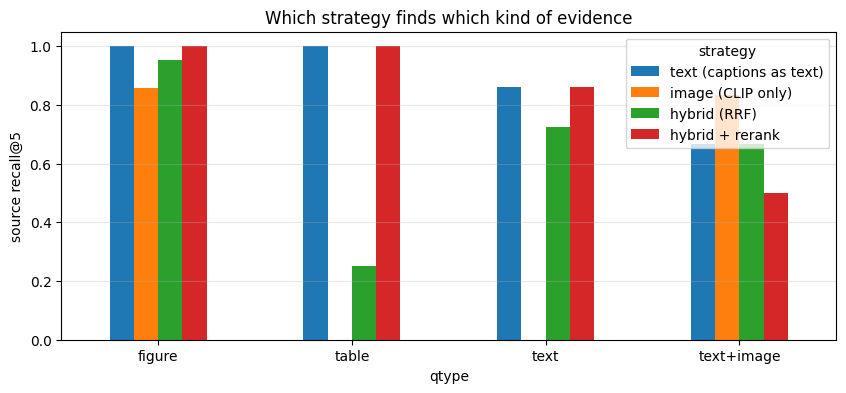

saved -> /content/week6_outputs/day4/day4_recall_by_type.png


In [31]:
STRATEGIES = {
    "text (captions as text)": dict(mode="text"),
    "image (CLIP only)": dict(mode="image"),
    "hybrid (RRF)": dict(mode="hybrid"),
    "hybrid + rerank": dict(mode="hybrid", reranker=RERANKER),
}


def first_rank(hits: list[dict], q: dict) -> int:
    return next((r for r, h in enumerate(hits, 1) if any(hit_matches(h, s) for s in q["sources"])), 999)


def run(strategy: dict, q: dict, k: int = K) -> tuple[list[dict], float]:
    img = Image.open(q["image_path"]) if q.get("image_path") else None
    t0 = time.perf_counter()
    hits = retrieve(INDEX, q["question"], img, k=k, **strategy)
    return hits, time.perf_counter() - t0


rows = []
for name, strat in STRATEGIES.items():
    for q in EVAL_QA:
        hits, dt = run(strat, q)
        r = first_rank(hits, q)
        rows.append({"strategy": name, "qid": q["id"], "qtype": q["qtype"], "recall@5": source_recall(hits, q),
                     "hit@1": r == 1, "mrr": 1 / r if r < 999 else 0.0, "ms": 1000 * dt})
RES = pd.DataFrame(rows)
RES.to_csv(OUTPUT_DIR / "day4_retrieval_per_question.csv", index=False)
BY_TYPE = RES.pivot_table(index="strategy", columns="qtype", values="recall@5").reindex(list(STRATEGIES))
OVERALL = RES.groupby("strategy")[["recall@5", "hit@1", "mrr", "ms"]].mean().reindex(list(STRATEGIES))
print("Source recall@5 by question type:\n", BY_TYPE.round(3).to_string())
print("\nOverall:\n", OVERALL.round(3).to_string())

fig, ax = plt.subplots(figsize=(10, 4))
BY_TYPE.T.plot.bar(ax=ax)
ax.set_ylim(0, 1.05)
ax.set_ylabel("source recall@5")
ax.set_title("Which strategy finds which kind of evidence")
ax.grid(axis="y", alpha=0.3)
plt.xticks(rotation=0)
save_fig(fig, "day4_recall_by_type.png")

## 5 · Text + image queries in detail

The query image is a **restyled** copy of one report's chart (different colours, size and title) — like a user photographing a slide. Three ways to use it:

6 text+image questions:
                         hit@1  recall@5
variant                                 
hybrid with image        0.333     0.667
image + text (composed)  0.833     0.833
image -> image           0.833     0.833
text only (no image)     0.167     0.500


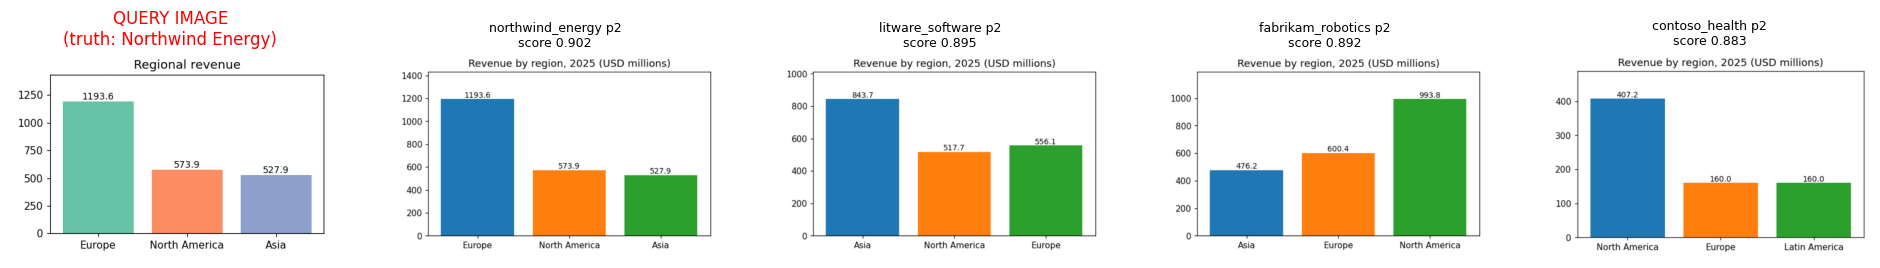

saved -> /content/week6_outputs/day4/day4_image_query.png


In [32]:
img_qs = [q for q in EVAL_QA if q["qtype"] == "text+image"]
rows = []
for q in img_qs:
    img = Image.open(q["image_path"])
    variants = {"text only (no image)": retrieve(INDEX, q["question"], None, k=K, mode="hybrid"),
                "image -> image": INDEX.search_by_image(img, None, k=K),
                "image + text (composed)": INDEX.search_by_image(img, q["question"], alpha=0.5, k=K),
                "hybrid with image": retrieve(INDEX, q["question"], img, k=K)}
    for name, hits in variants.items():
        rows.append({"variant": name, "qid": q["id"], "hit@1": first_rank(hits, q) == 1, "recall@5": source_recall(hits, q)})
IMG_RES = pd.DataFrame(rows).groupby("variant")[["hit@1", "recall@5"]].mean()
print(f"{len(img_qs)} text+image questions:\n{IMG_RES.round(3).to_string()}")

q = img_qs[0]
hits = INDEX.search_by_image(Image.open(q["image_path"]), None, k=4)
fig, axes = plt.subplots(1, 5, figsize=(24, 4.5))
axes[0].imshow(Image.open(q["image_path"]))
axes[0].set_title(f"QUERY IMAGE\n(truth: {q['answer']})", color="red")
for ax, h in zip(axes[1:], hits):
    ax.imshow(Image.open(h["image_path"]))
    ax.set_title(f"{h['doc_id']} p{h['page']}\nscore {h['score']:.3f}", fontsize=9)
for ax in axes:
    ax.axis("off")
save_fig(fig, "day4_image_query.png")

Restyling changes colours and titles, yet CLIP still matches the right chart **when the data shape is distinctive**; two pie charts with similar slices are where it fails. Remember Day 2: CLIP cannot read whose chart it is — the *answer* (company name) comes from the matched item's metadata, not from the pixels.

## 6 · Cross-modal retrieval in both directions

- **Text → figure:** a figure question should surface a figure, not a paragraph that mentions the figure.
- **Image → text:** an image query finds a figure; *page-neighbour expansion* then pulls in the text and tables on the same page — the context needed to explain the figure.

In [33]:
def expand_neighbours(hits: list[dict], per_hit: int = 2) -> list[dict]:
    out = list(hits)
    seen = {h["id"] for h in hits}
    for h in hits:
        near = [it for it in INDEX.items if it["doc_id"] == h["doc_id"] and h["page"] in it["pages"]
                and it["type"] in ("text", "table") and it["id"] not in seen][:per_hit]
        for it in near:
            seen.add(it["id"])
            out.append({**it, "score": 0.0, "space": f"neighbour of {h['id']}"})
    return out


fig_qs = [q for q in EVAL_QA if q["qtype"] == "figure"]
share_fig = {name: np.mean([retrieve(INDEX, q["question"], k=1, **s)[0]["type"] == "figure" for q in fig_qs])
             for name, s in STRATEGIES.items()}
print("Figure questions whose top-1 hit is a figure:", {k: round(v, 3) for k, v in share_fig.items()})

q = img_qs[1 % len(img_qs)]
expanded = expand_neighbours(INDEX.search_by_image(Image.open(q["image_path"]), None, k=1))
print(f"\nimage query ({q['id']}) -> figure + same-page text:")
for h in expanded:
    print(f"  [{h['type']:6s}] {h['id']:32s} {h.get('space', ''):28s} {h['text'][:90]!r}")

Figure questions whose top-1 hit is a figure: {'text (captions as text)': np.float64(0.476), 'image (CLIP only)': np.float64(1.0), 'hybrid (RRF)': np.float64(0.905), 'hybrid + rerank': np.float64(0.905)}

image query (contoso_health-img-pie) -> figure + same-page text:
  [figure] contoso_health:figure2           clip_image->image            'Contoso Health Annual Report 2025 > Business segments\nFigure on page 3. Figure 2: Revenue '
  [text  ] contoso_health:text4             neighbour of contoso_health:figure2 'Contoso Health Annual Report 2025 > Business segments\nContoso Health operates 3 business s'
  [text  ] contoso_health:text5             neighbour of contoso_health:figure2 'Contoso Health Annual Report 2025 > Outlook\nManagement targets revenue growth of 4% in 202'


## 7 · How deep should we retrieve?

Recall keeps rising with k, but every extra item is more context for the generator to read (Day 5) — and more chances to be distracted.

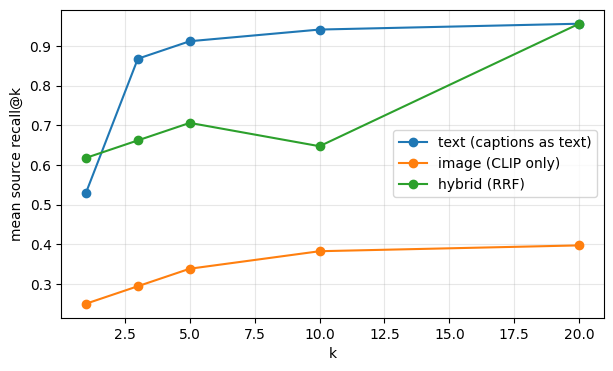

saved -> /content/week6_outputs/day4/day4_recall_vs_k.png


In [34]:
ks = [1, 3, 5, 10, 20]
curve = {name: [np.mean([source_recall(run(s, q, k)[0], q) for q in EVAL_QA]) for k in ks]
         for name, s in STRATEGIES.items() if "rerank" not in name}
fig, ax = plt.subplots(figsize=(7, 4))
for name, vals in curve.items():
    ax.plot(ks, vals, "o-", label=name)
ax.set_xlabel("k")
ax.set_ylabel("mean source recall@k")
ax.legend()
ax.grid(alpha=0.3)
save_fig(fig, "day4_recall_vs_k.png")

## 8 · What does hybrid still miss?

In [35]:
miss = RES[(RES.strategy == "hybrid + rerank") & (RES["recall@5"] < 1)]
qa_by_id = {q["id"]: q for q in EVAL_QA}
for _, r in miss.head(10).iterrows():
    q = qa_by_id[r.qid]
    hits, _ = run(STRATEGIES["hybrid + rerank"], q)
    print(f"[{q['qtype']}] {q['question']}\n   expected {q['sources']} | got {[(h['doc_id'], h['page'], h['type']) for h in hits[:3]]}")
print(f"\n{len(miss)} of {RES[RES.strategy == 'hybrid + rerank'].shape[0]} questions not fully covered by hybrid + rerank")

(OUTPUT_DIR / "day4_summary.json").write_text(json.dumps({
    "by_type": BY_TYPE.round(4).to_dict("index"), "overall": OVERALL.round(4).to_dict("index"),
    "image_queries": IMG_RES.round(4).to_dict("index"), "recall_vs_k": {"k": ks, **curve},
}, indent=2, default=float), encoding="utf-8")
print("saved ->", OUTPUT_DIR / "day4_summary.json")

[text+image] Which company's annual report contains a chart showing the same data as this image?
   expected [['northwind_energy', 2, 'figure']] | got [('northwind_energy', 3, 'figure'), ('litware_software', 3, 'figure'), ('fabrikam_robotics', 3, 'figure')]
[text+image] Which company's annual report contains a chart showing the same data as this image?
   expected [['contoso_health', 3, 'figure']] | got [('northwind_energy', 3, 'figure'), ('litware_software', 3, 'figure'), ('fabrikam_robotics', 3, 'figure')]
[text+image] Which company's annual report contains a chart showing the same data as this image?
   expected [['tailspin_air', 2, 'figure']] | got [('northwind_energy', 3, 'figure'), ('litware_software', 3, 'figure'), ('fabrikam_robotics', 3, 'figure')]
[text] Who is the chief executive officer of Proseware Foods?
   expected [['proseware_foods', 1, 'text']] | got [('proseware_foods', 1, 'table'), ('proseware_foods', 3, 'text'), ('litware_software', 1, 'text')]
[text] In which city

## Checklist

- [ ] Recall by question type for text-only, image-only, hybrid and hybrid + rerank — and which wins where.
- [ ] Text+image queries: image→image vs composed vs text-only measured.
- [ ] A text query returns a figure; an image query returns related text through page neighbours.
- [ ] I picked k from the recall-vs-k curve.

**Next (Day 5):** give the retrieved text, tables *and images* to a VLM, and get a grounded, cited answer.